# Basic extraction of MIRI (LRS) slitless observations

- Subtract background by simply taking differences of offset exposures
- Currently no accounting for contamination other than masking "very negative" pixels where a bright source in the offset position was subtracted

In [6]:
import os

WORK = "/Users/gbrammer/Research/JWST/Projects/MIRI-LRS/Workdir"
if os.path.exists(WORK):
    os.chdir(WORK)

import yaml
import logging

import matplotlib.pyplot as plt
import numpy as np
import astropy.io.fits as pyfits
import astropy.wcs as pywcs
import gwcs

import scipy.ndimage as nd

import os
import glob
import jwst.datamodels
from jwst.pipeline import Spec2Pipeline, Spec3Pipeline, Image2Pipeline

from grizli import jwst_utils

jwst_utils.QUIET_LEVEL = logging.CRITICAL
jwst_utils.set_quiet_logging(level=logging.CRITICAL)

from grizli import utils

import mastquery.utils

import msaexp.spectrum
from msaexp.cloud import lrs

utils.LOGFILE = "lrs_processing.log.txt"

_ = utils.log_comment(utils.LOGFILE, "Processing started", verbose=True, show_date=True)

# (2026-11-13 23:22:27.095)
Processing started


In [7]:
from importlib import import_module

for module in ["grizli", "msaexp", "jwst", "astropy"]:
    mod = import_module(module)
    print(f"{module}=={mod.__version__}")

grizli==1.14.4.dev5+g2edba480a.d20261113
msaexp==0.9.20
jwst==1.16.1
astropy==7.2.1


# Config

Define groups of ``rate`` files to be differenced for background removal.

For this example, use observations from [GO-4533](https://www.stsci.edu/jwst-program-info/program/?program=4533) (PI: G. Oestlin) that include a source observed both through the LRS slit and in the slitless area.

In [8]:
# GOODS-South source with target in both LRS slit and slitless

config = yaml.load("""
root: gds-jw04533
groups:
    jw04533001001a: 
     - jw04533001001_02102_00001_mirimage_rate.fits
     - jw04533001001_02102_00002_mirimage_rate.fits
    jw04533001001b: 
     - jw04533001001_02104_00001_mirimage_rate.fits
     - jw04533001001_02104_00002_mirimage_rate.fits
    jw04533001001c: 
     - jw04533001001_02106_00001_mirimage_rate.fits
     - jw04533001001_02106_00002_mirimage_rate.fits
    jw04533002001a: 
     - jw04533002001_02102_00001_mirimage_rate.fits
     - jw04533002001_02102_00002_mirimage_rate.fits
    jw04533002001b: 
     - jw04533002001_02102_00003_mirimage_rate.fits
     - jw04533002001_02102_00004_mirimage_rate.fits
""", Loader=yaml.Loader)



In [9]:
rate_files = []
for group in config["groups"]:
    rate_files.extend(config["groups"][group])

files_exist = np.array([os.path.exists(file) for file in rate_files])

if np.sum(files_exist) < len(files_exist):
    print(f"Download {(~files_exist).sum()} files:")
    result = mastquery.utils.download_from_mast(rate_files)
else:
    print(f"All {len(rate_files)} rate files found.")

All 10 rate files found.


## Read rate files

In [10]:
lrs.load_rate_files?

Signature: lrs.load_rate_files(files, write_bkg_files=True)
Docstring:
Load rate files, take diffs to remove background

Parameters
----------
files : list
    List of ``rate.fits`` or ``rate_bkg.fits`` files. Generally these
    should just be files from a single visit, as differences are taken
    between files at different ``x_offset`` positions to remove the
    background and images from even slightly different epochs generally
    don't subtract perfectly.

write_bkg_files : bool
    Save ``rate_bkg.fits`` files of the difference products for fast
    reproduction later.

Returns
-------
result : dict
    Loaded image data with keys:
      - ``files`` = list of the original files
      - ``dms`` = list of ``jwst.datamodels.ImageModel`` objects
      - ``sky_arrays`` = ndarray of the sky data
      - ``sky_var`` = ndarray of the sky variance
      - ``wcs_list`` = list of ``astropy.wcs.WCS`` objects for each exposure
File:      ~/miniconda3/envs/jw312-2025/lib/python3.12/site-pack

In [11]:
rate_groups = {}

for i, group in enumerate(config["groups"]):
    
    utils.log_comment(
        utils.LOGFILE,
        f"\nGroup {i+1}/{len(config['groups'])}: {group}  N={len(config['groups'][group])} files\n",
        verbose=True,
        show_date=True
    )
    
    rate_groups[group] = lrs.load_rate_files(config["groups"][group])

# (2026-11-13 23:22:36.630)

Group 1/5: jw04533001001a  N=2 files



2026-11-14 00:22:37,452 - stpipe.AssignWcsStep - INFO - AssignWcsStep instance created.


i=0  offset=( -0.95,  -0.41) (xoff= -0.9)  nsky=1
i=1  offset=(  0.94,  -0.41) (xoff=  0.9)  nsky=1


2026-11-14 00:22:39,434 - stpipe.AssignWcsStep - INFO - AssignWcsStep instance created.


# (2026-11-13 23:22:40.051)

Group 2/5: jw04533001001b  N=2 files

i=0  offset=( -0.95,  -0.00) (xoff= -0.9)  nsky=1
i=1  offset=(  0.95,   0.00) (xoff=  0.9)  nsky=1


2026-11-14 00:22:40,283 - stpipe.AssignWcsStep - INFO - AssignWcsStep instance created.
2026-11-14 00:22:41,109 - stpipe.AssignWcsStep - INFO - AssignWcsStep instance created.
2026-11-14 00:22:41,928 - stpipe.AssignWcsStep - INFO - AssignWcsStep instance created.


... (2 outputs left out)

# (2026-11-13 23:22:43.234)

Group 4/5: jw04533002001a  N=2 files

i=0  offset=(  9.00,  -2.00) (xoff=  9.0)  nsky=1
i=1  offset=( 16.00,  -2.00) (xoff= 16.0)  nsky=1


2026-11-14 00:22:43,558 - stpipe.AssignWcsStep - INFO - AssignWcsStep instance created.
2026-11-14 00:22:44,338 - stpipe.AssignWcsStep - INFO - AssignWcsStep instance created.


# (2026-11-13 23:22:44.967)

Group 5/5: jw04533002001b  N=2 files

i=0  offset=(  9.00,   8.00) (xoff=  9.0)  nsky=1
i=1  offset=( 16.00,   8.00) (xoff= 16.0)  nsky=1


2026-11-14 00:22:45,189 - stpipe.AssignWcsStep - INFO - AssignWcsStep instance created.
2026-11-14 00:22:45,903 - stpipe.AssignWcsStep - INFO - AssignWcsStep instance created.


In [12]:
# Region files with illuminated exposure footprints
lrs.rate_group_regions?

Signature:
lrs.rate_group_regions(
    rate_groups,
    root='group',
    separate_region_files=False,
    write_file=True,
    make_figure=True,
    figsize=(8, 8),
    **kwargs,
)
Docstring:
Make region file(s) for the illuminated portions of the loaded exposures

Parameters
----------
rate_groups : dict
    Output from `~msaexp.cloud.lrs.load_rate_files`

root : str
    String prefix for output products, i.e., ``{root}_miri_lrs.reg``.

separate_region_files : bool
    Make separate region files for each group

make_figure : bool
    Make a summary figure

figsize : (float, float)
    Figure size

kwargs : dict
    Keyword arguments passed through to `msaexp.cloud.lrs.miri_illum_window`

Returns
-------
sregions : list
    List of `sregion.SRegion` objects

fig : figure or None
    Output figure object.  Also saved to ``{root}_miri_lrs.png``.
File:      ~/miniconda3/envs/jw312-2025/lib/python3.12/site-packages/msaexp/cloud/lrs.py
Type:      function

In [13]:
smiles_nirspec = utils.read_catalog(
    "https://archive.stsci.edu/hlsps/smiles/dr2/hlsp_smiles_jwst_nirspec_goodss_multi_v1.0_catalog.fits"
)

with pyfits.open(
    "https://archive.stsci.edu/hlsps/smiles/dr1/hlsp_smiles_jwst_miri_goodss_multi_v1.0_catalog.fits",
) as hdul:
    smiles_miri = utils.read_catalog(hdul["CIRC"])

so = np.argsort(smiles_miri["F560W_CIRC4"])[::-1]
smiles_miri = smiles_miri[so]

idx, dr = smiles_miri.match_to_catalog_sky(smiles_nirspec)
hasm = dr.value < 0.2

smiles_nirspec = smiles_nirspec[hasm]
for c in smiles_miri.colnames:
    if c not in smiles_nirspec.colnames:
        smiles_nirspec[c] = smiles_miri[c][idx[hasm]]

so = np.argsort(smiles_nirspec["F560W_CIRC4"])[::-1]
smiles_nirspec = smiles_nirspec[so]


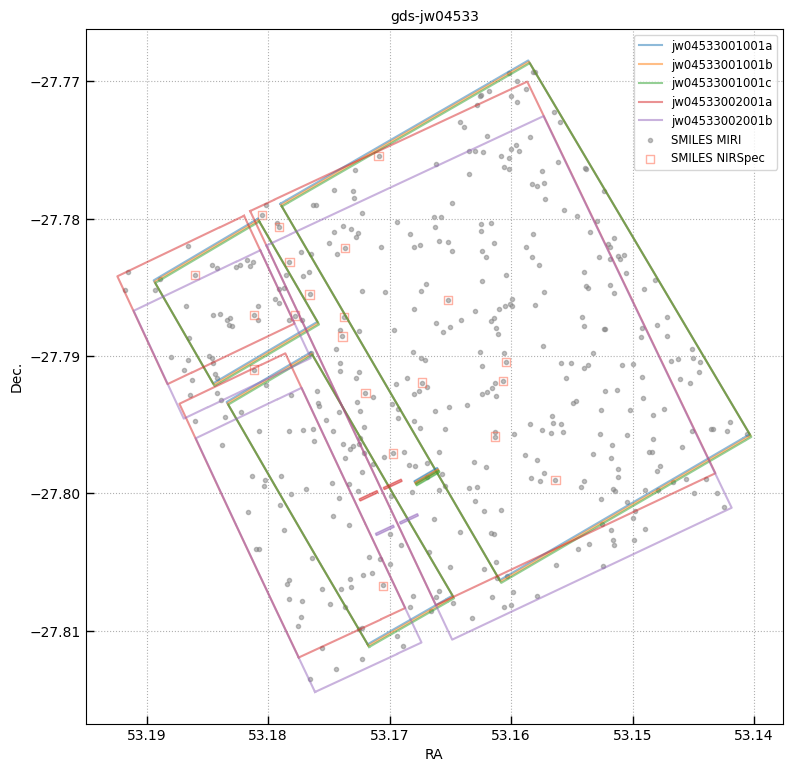

In [14]:
sregions, fig = lrs.rate_group_regions(rate_groups, root=config["root"], separate_region_files=True)

## Overplot SMILES sources
smiles_nirspec["in_lrs"] = False
coo_nirspec = np.array([smiles_nirspec["RA"], smiles_nirspec["DEC"]]).T

for sr in sregions:
    for path in sr.path:
        smiles_nirspec["in_lrs"] |= path.contains_points(coo_nirspec)

smiles_miri["in_lrs"] = False
coo_miri = np.array([smiles_miri["RA"], smiles_miri["DEC"]]).T

for sr in sregions:
    for path in sr.path:
        smiles_miri["in_lrs"] |= path.contains_points(coo_miri)

ax = fig.axes[0]
ax.scatter(*coo_miri[smiles_miri["in_lrs"],:].T, marker='.', alpha=0.5, label="SMILES MIRI", color="0.5")

ax.scatter(*coo_nirspec[smiles_nirspec["in_lrs"],:].T, marker='s', alpha=0.5, label="SMILES NIRSpec", ec="tomato", fc="None")

ax.legend()

smiles_miri = smiles_miri[smiles_miri["in_lrs"]]


In [15]:
# Drizzled mosaics of group exposures
lrs.rate_group_mosaic?

Signature:
lrs.rate_group_mosaic(
    rate_groups,
    root='jw09615',
    output_path='./',
    make_separate=True,
    make_combined=True,
    pixel_scale=0.11057,
    kernel='square',
    pixfrac=0.5,
    verbose=True,
)
Docstring:
Make drizzled mosaics of group exposures

Parameters
----------
rate_groups : dict
    Output from `~msaexp.cloud.lrs.load_rate_files`

root : str
    String prefix for output products, i.e., ``{root}_miri_lrs.reg``.

output_path : str
    Location for output files.  If None, just return arrays.

make_separate : bool
    Make drizzled combinations separated for each group with their own
    pixel grid.

make_combined : bool
    Make combination of exposures in all groups

pixel_scale, kernel, pixfrac : float, str, float
    Drizzle parameters

Returns
-------
products : dict
    Dictionary with keys of the drizzled groups and values of the
    output from `grizli.utils.drizzle_array_groups`.
File:      ~/miniconda3/envs/jw312-2025/lib/python3.12/site-pack

In [16]:
products = lrs.rate_group_mosaic(rate_groups, root=config['root'], verbose=2)


Group mosaic 1/5 jw04533001001a  N=2 files

  0/  2: WCS[SCI,0]    3.67
  1/  2: WCS[SCI,0]    3.73

  Mosaic WCS: (53.16493,-27.79014) 2.8'x2.8'  0.111"/pix



The following task in the stsci.skypac package can be run with TEAL:
                                    skymatch                                    
2026318002434 INFO src=drizzlepac.haputils.astrometric_utils- ASTROMETRIC_CATALOG_URL = http://gsss.stsci.edu/webservices
The following tasks in the drizzlepac package can be run with TEAL:
    astrodrizzle       config_testbed      imagefindpars           mapreg       
       photeq            pixreplace           pixtopix            pixtosky      
  refimagefindpars       resetbits          runastrodriz          skytopix      
     tweakback            tweakreg           updatenpol
# (2026-11-13 23:24:35.024)
Drizzle array 1/2
# (2026-11-13 23:24:35.135)
Drizzle array 2/2
Write group mosaic ./jw04533001001a_miri_lrs_sci.fits

Group mosaic 2/5 jw04533001001b  N=2 files

  0/  2:

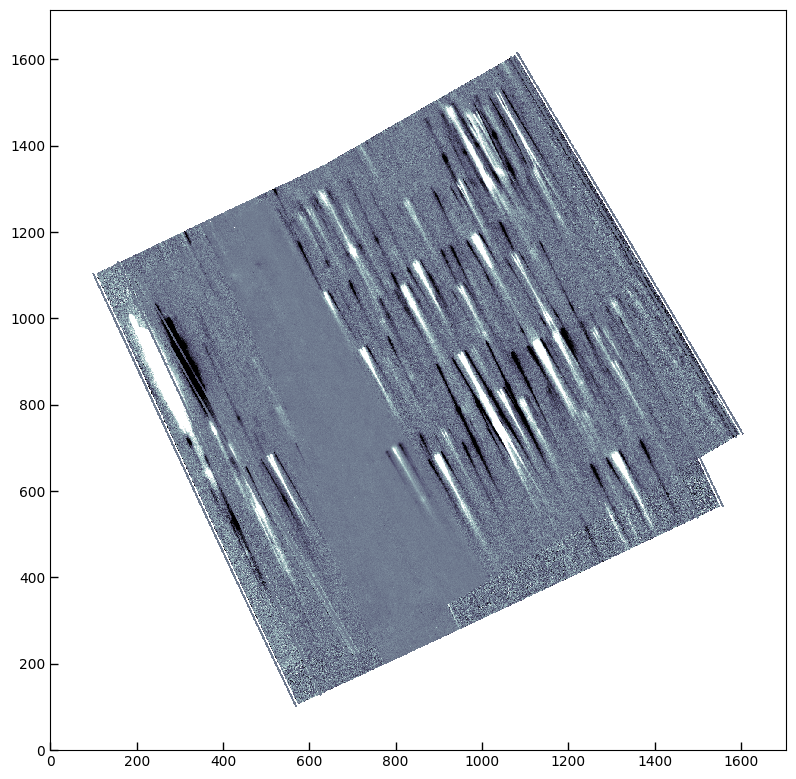

In [20]:
with pyfits.open(f"{config['root']}_miri_lrs_sci.fits") as im:
    mosaic_data = im[0].data

fig, ax = plt.subplots(1,1,figsize=(8,8))

ax.imshow(mosaic_data * np.nan**(mosaic_data == 0), vmin=-0.3, vmax=0.3, cmap="bone")

fig.tight_layout(pad=1)


# Slitless processing

## Extract slitless spectrum by position

### Set position

In [21]:
coords = """

# Source in LRS slit and slitless area
# https://s3.amazonaws.com/msaexp-nirspec/miri-lrs/jw04533001-mds.-deep-survey-alma-10_lrs.spec.fits
53.166943 -27.798828

# Other PAH sources
53.1726177 -27.7810377
53.1623705 -27.7751336

# Very bright with PAH
53.1616034 -27.7923319

""".strip().split("\n")[-1]

ra, dec = np.array(coords.split()[:2]).astype(float)

pos_key = f"{ra:.6f}_{dec:.6f}"

ra, dec, pos_key

(53.1616034, -27.7923319, '53.161603_-27.792332')

In [22]:
if 0:
    # Step through SMILES
    j = -1

In [23]:
if 0:
    j += 1
    
    if 0:
        subset = smiles_nirspec["in_lrs"] & (smiles_nirspec["Q"] == "A")
        ra = smiles_nirspec[subset]["RA"][j]
        dec = smiles_nirspec[subset]["DEC"][j]        
        smiles_nirspec[subset]["NIRCAM_ID", "RA", "DEC", "Z_SPEC", "KEYWORDS", "F560W_CIRC3"][j:j+1].pprint_all()
    
    else:
    
        smiles_miri["ID", "RA", "DEC", "F560W_CIRC4", "F770W_CIRC4"][j:j+1].pprint_all()
        ra = smiles_miri["RA"][j]
        dec = smiles_miri["DEC"][j]
        
    pos_key = f"{ra:.6f}_{dec:.6f}"


 0 jw04533001001_02102_00001_mirimage_rate.fits
   corner offset:    0.78  -1.73
    pixel offset:  230.59  98.63
 1 jw04533001001_02102_00002_mirimage_rate.fits
   corner offset:    0.82  -1.67
    pixel offset:  247.72  98.78
 2 jw04533001001_02104_00001_mirimage_rate.fits
   corner offset:    0.78  -1.74
    pixel offset:  230.60 102.35
 3 jw04533001001_02104_00002_mirimage_rate.fits
   corner offset:    0.83  -1.69
    pixel offset:  247.74 102.46
 4 jw04533001001_02106_00001_mirimage_rate.fits
   corner offset:    0.78  -1.75
    pixel offset:  230.62 106.05
 5 jw04533001001_02106_00002_mirimage_rate.fits
   corner offset:    0.83  -1.70
    pixel offset:  247.76 106.16
 6 jw04533002001_02102_00001_mirimage_rate.fits
   corner offset:    1.00  -1.38
    pixel offset:  310.65 105.25
 7 jw04533002001_02102_00002_mirimage_rate.fits
   corner offset:    1.16  -0.90
    pixel offset:  374.06 105.97
 8 jw04533002001_02102_00003_mirimage_rate.fits
   corner offset:    1.04  -1.15
    pix

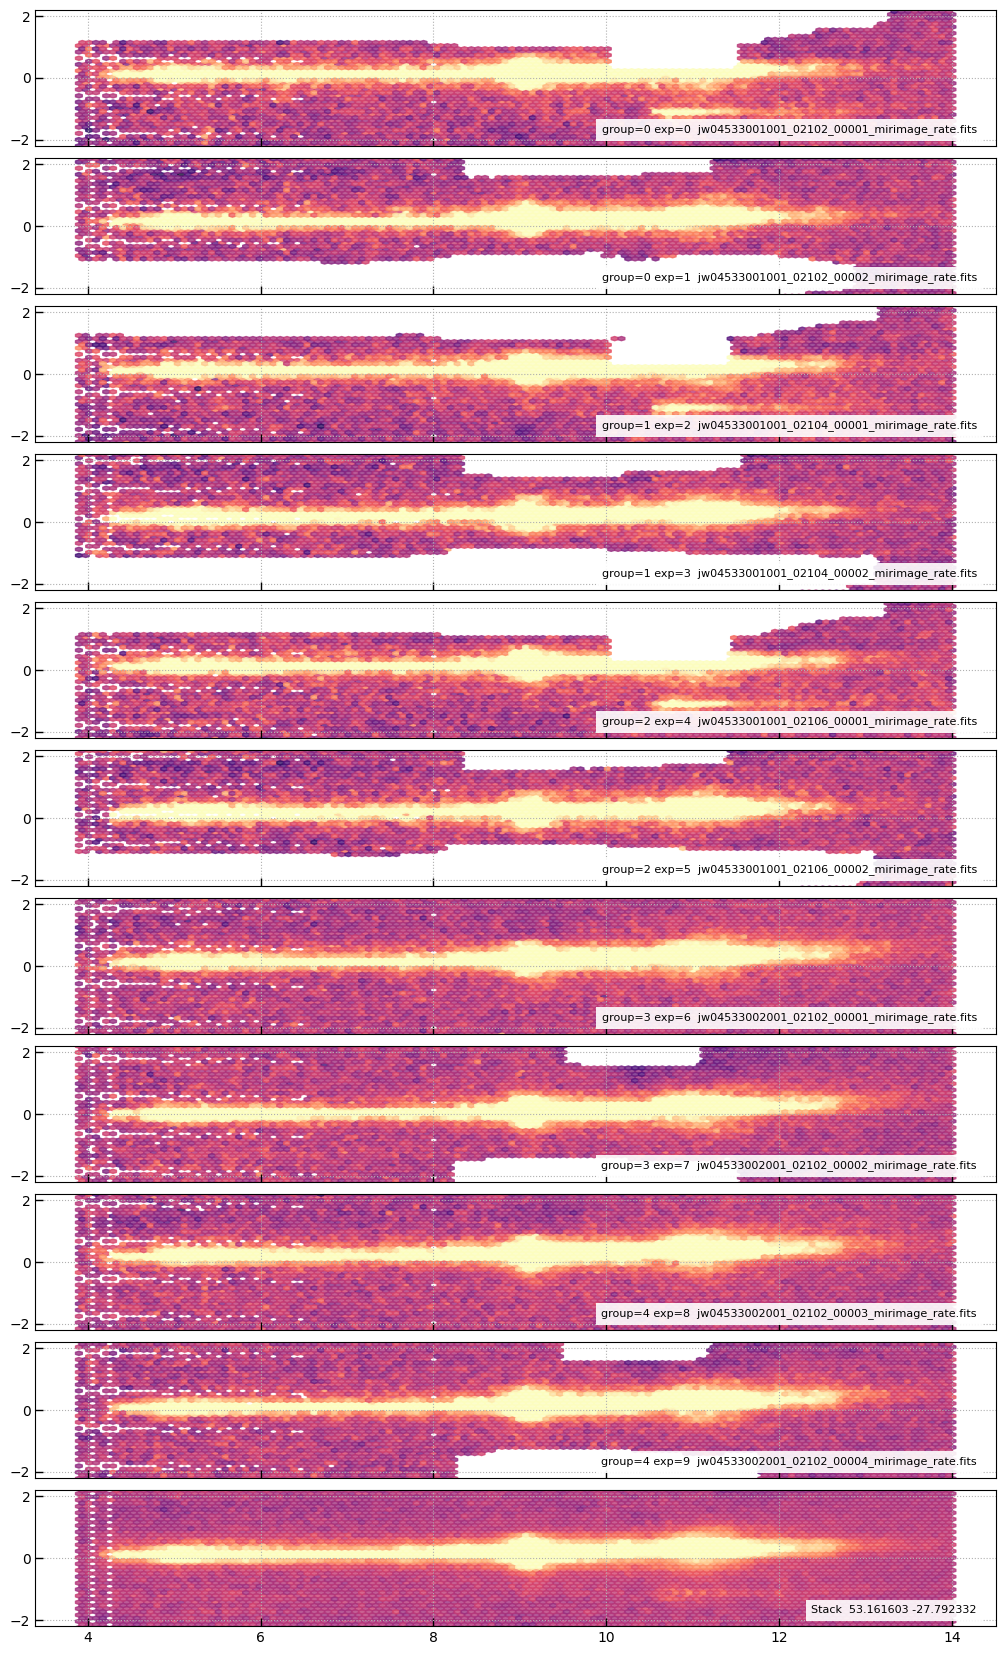

In [24]:
# Get the cutouts

fig, data = lrs.cutout_pixel_table(ra, dec, rate_groups, make_figure=True, subtract_pedestal=True, check_window=True)

if fig is not None:
    fig.savefig(f"{config['root']}_{pos_key}_exposures.png")

group_names, ung = lrs.slitless_data_groups(data, config["groups"])


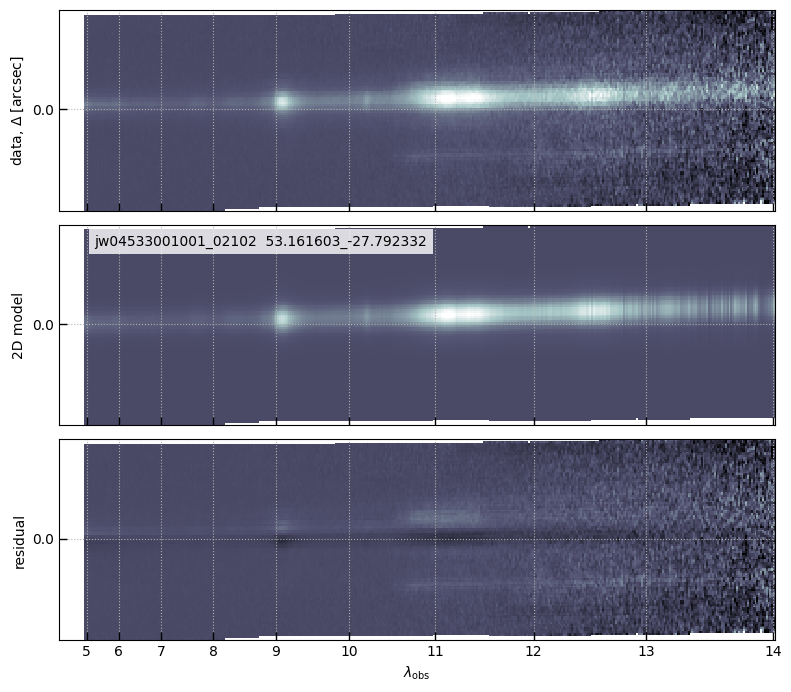

In [25]:
if 0:
    # Manually mask some contamination in the Monster
    une = utils.Unique(data["exposure"], verbose=False)
    bad = (data["wave"] > 12) # & (~np.isin(data["exposure"], [8, 9]))
    bad = (data["wave"] > 13.4) # & (~np.isin(data["exposure"], [8, 9]))
    data["data"][bad] = np.nan

if 0:
    bad = (data["dx"] > 0.4) & (data["wave"] > 9.1)
    bad = (data["dx"] < -1)
    bad = (data["dx"] > 1.2) & (data["wave"] >10.5)
    bad = (data["dx"] < -1.2)
    data["data"][bad] = np.nan

if 0:
    data = lrs.get_data_slice(data, (data["exposure"] == 14))

psf_data = lrs.evaluate_model_psf(
    data, np.array([0.2, 0.25, 0.15]), do_optimal_extraction=True
)

_ = lrs.process_2d_products(data, recenter=False)


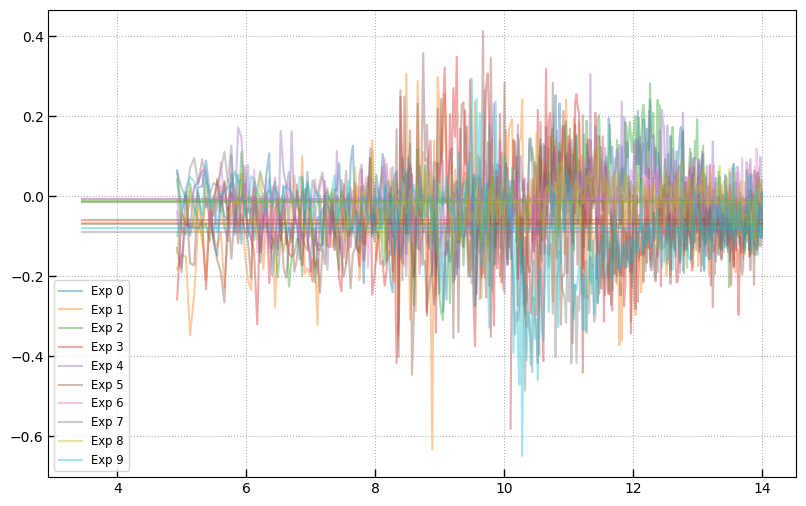

In [28]:
# Bkg pedestal
from scipy.stats import binned_statistic

SUBTRACT_EXTRA = False

une = utils.Unique(data["exposure"], verbose=False)

fig, ax = plt.subplots(1,1,figsize=(8, 5))

xwbin = np.linspace(-1,1, len(data["wbin"]))
xwb = np.interp(data["wave"], data["wbin"], xwbin)

for exp in une.values:
    sub = une[exp] & (np.abs(data["dx"]) > 1.4) & np.isfinite(data["data"])
    sub &= data["data"] < 3 * data["err"]
    wsub = data["wave"] > 1.8
    # wsub = data["wave"] < 10
    
    # wsub = data["wave"] < 10
    sub &= wsub
    if sub.sum() == 0:
        continue
        
    stat = binned_statistic(data["wave"][sub], data["data"][sub], statistic="median", bins=data["wbin_edge"])

    pl = ax.plot(data["wbin"], stat.statistic, label=f"Exp {exp}", alpha=0.4)
    ok = np.isfinite(stat.statistic)
    
    c = np.polyfit(xwbin[ok], stat.statistic[ok], 0)
    ax.plot(data["wbin"], np.polyval(c, xwbin), color=pl[0].get_color(), alpha=0.4)

    if SUBTRACT_EXTRA == False:
        data["data"][une[exp]] -= np.polyval(c, xwb[une[exp]])
    
ax.grid()
ax.legend()
fig.tight_layout(pad=0.5)


In [29]:
# Initialize trace parameters
group_theta = {}

ung = utils.Unique(np.array(data["meta"]["group_names"])[data["group"]], verbose=True)

for ig in ung.values:
    group_theta[ig] = np.array([0.12, 0.21, 0.1])


   N  value     
====  ==========
24340  jw04533001001a
24142  jw04533001001b
24222  jw04533001001c
31070  jw04533002001a
30845  jw04533002001b


In [30]:
if 0:
    # check delta chi2
    shifts = np.arange(-0.2, 0.41, 0.1)
    sizes = np.arange(0, 0.21, 0.05)
    
    theta = []
    chi2 = []
    
    for sh in shifts:
        for si in sizes:
            theta_i = [sh, si]
            psf_data = lrs.evaluate_model_psf(
                data, theta_i, do_optimal_extraction=True
            )
            theta.append(theta_i)
            chi2.append(data["chi2"])
    
            print(f"{theta_i[0]:5.1f} {theta_i[1]:5.1f}  {chi2[-1]:>10.3f}")
            
    t = utils.GTable()
    t["theta"] = theta
    t["chi2"] = chi2
    # t.pprint_all()
    
    print(theta[np.argmin(chi2)])

### Fit shifts and profile size


Exposure group jw04533001001a  (1 / 5)  npix=8409
    result = [0.13487039 0.2925941  0.12258149]

Exposure group jw04533001001b  (2 / 5)  npix=8487
    result = [0.1397002  0.29705755 0.12258149]

Exposure group jw04533001001c  (3 / 5)  npix=8495
    result = [0.14987361 0.30269422 0.12258149]

Exposure group jw04533002001a  (4 / 5)  npix=10520
    result = [0.22330314 0.28765416 0.12258149]

Exposure group jw04533002001b  (5 / 5)  npix=10311
    result = [0.21804851 0.36096962 0.12258149]


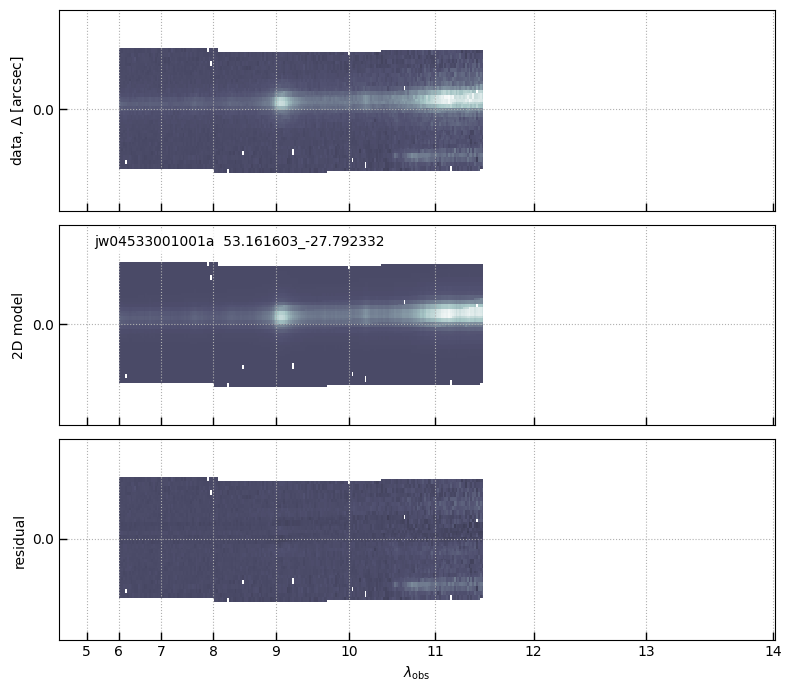

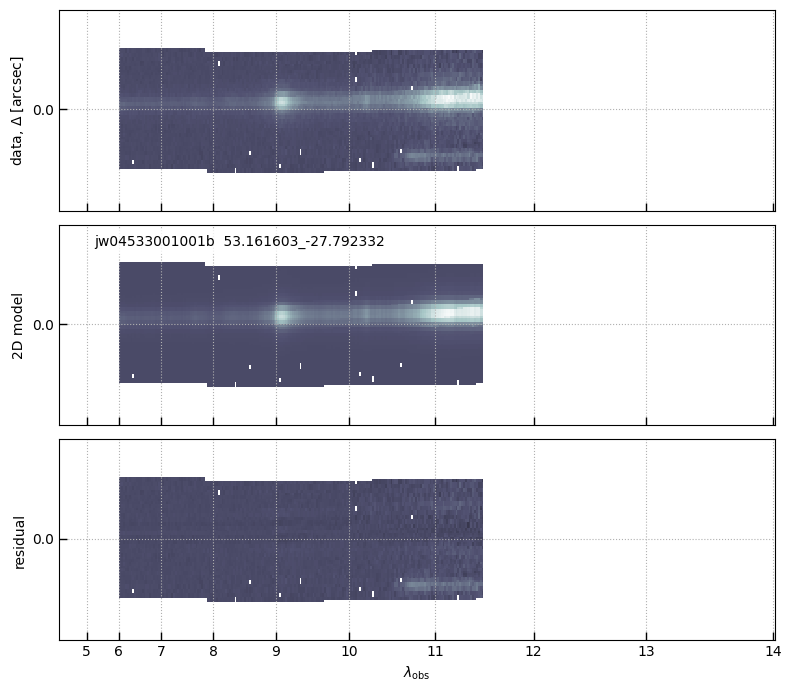

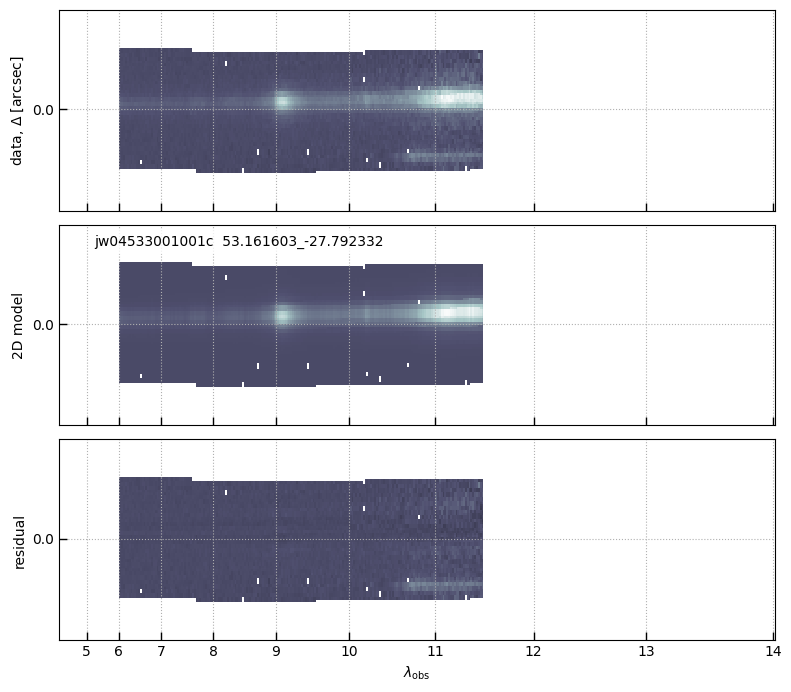

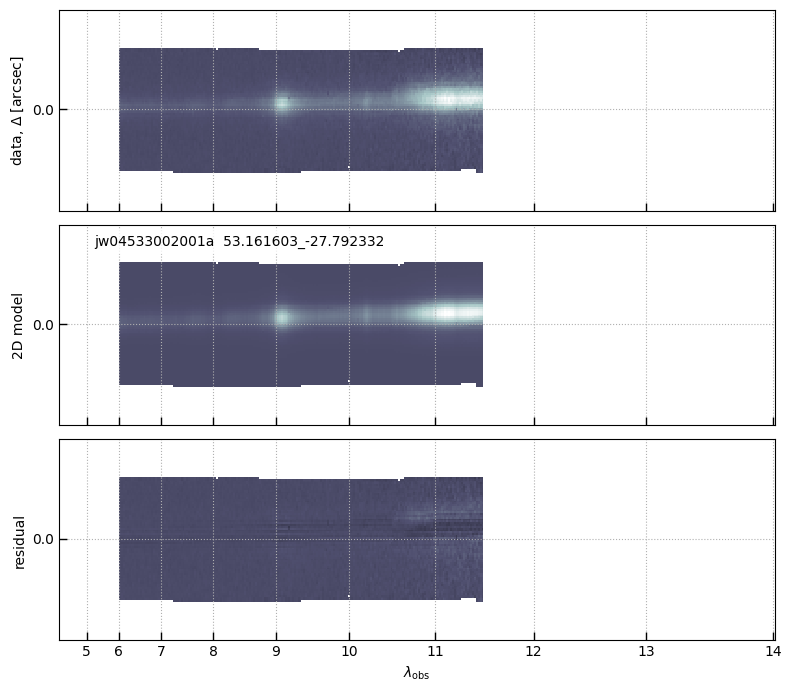

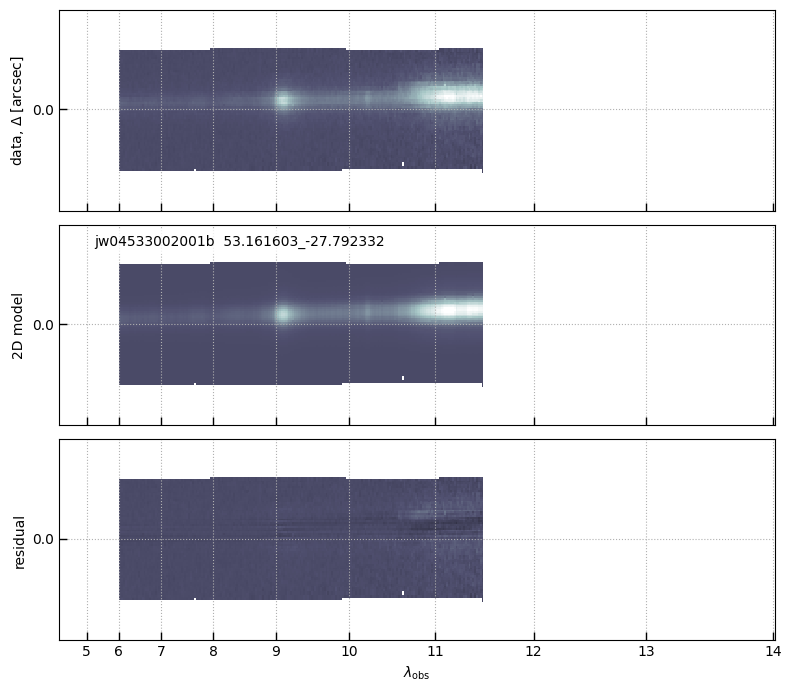

In [31]:
# Do the fit
ung, group_theta = lrs.slitless_trace_by_group(
    data, verbose=1,
    method="bfgs", tol=1.e-4,
    reset_initial=True,
    initial_size=0.08,
    fit_size=True,
    show_each_2d=True,
    fix_first_size=True,  # Force sizes to be the same as the first
    fix_first_shift=False,
)

### Final combination

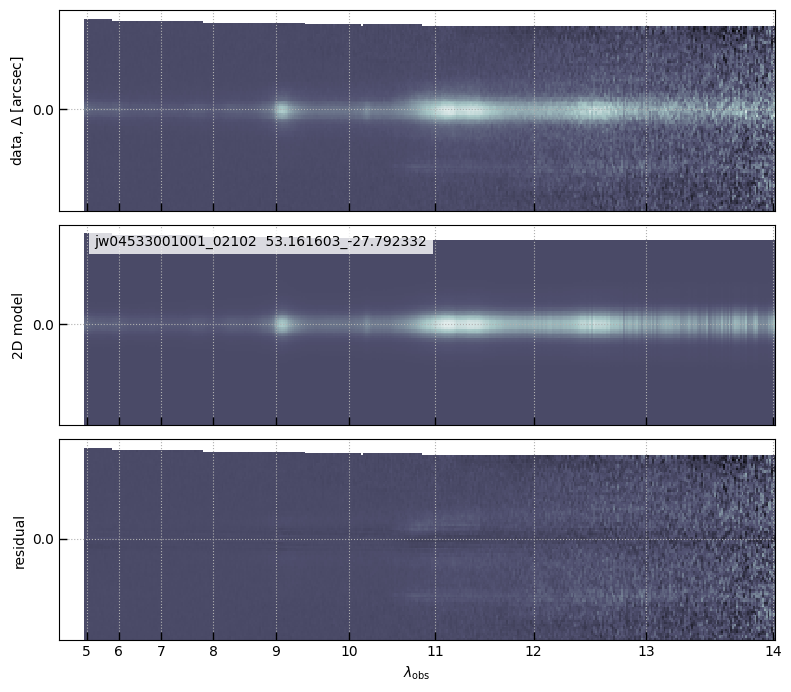

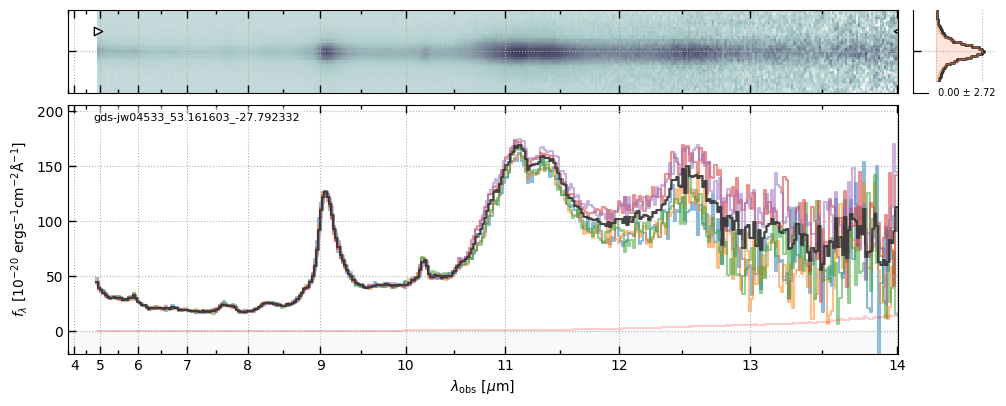

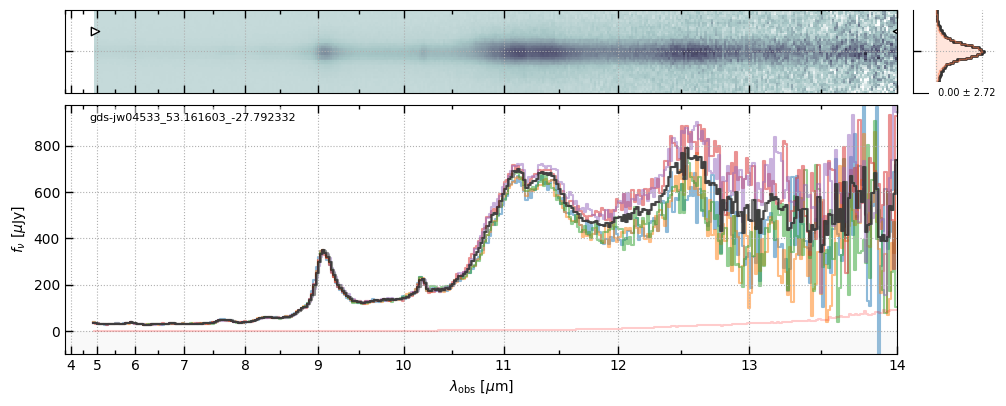

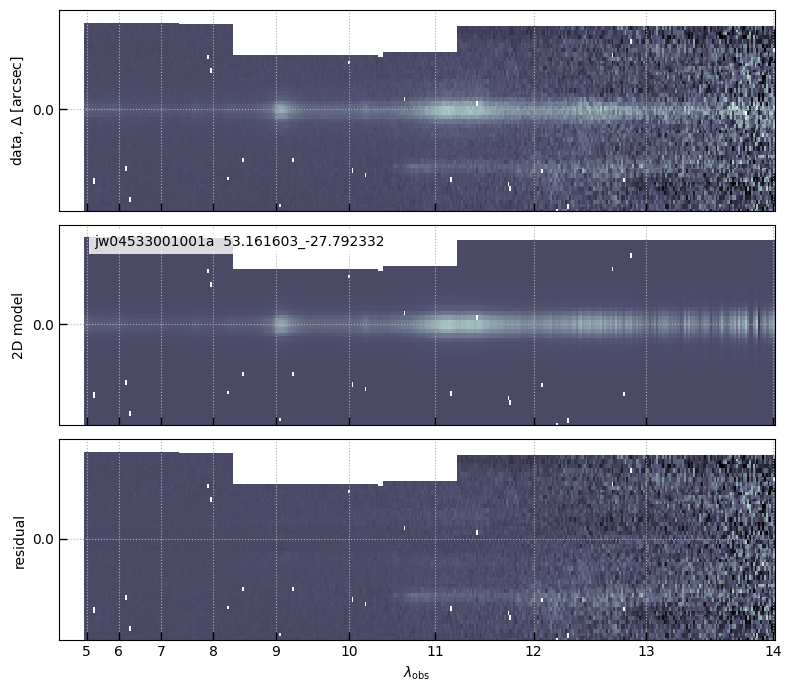

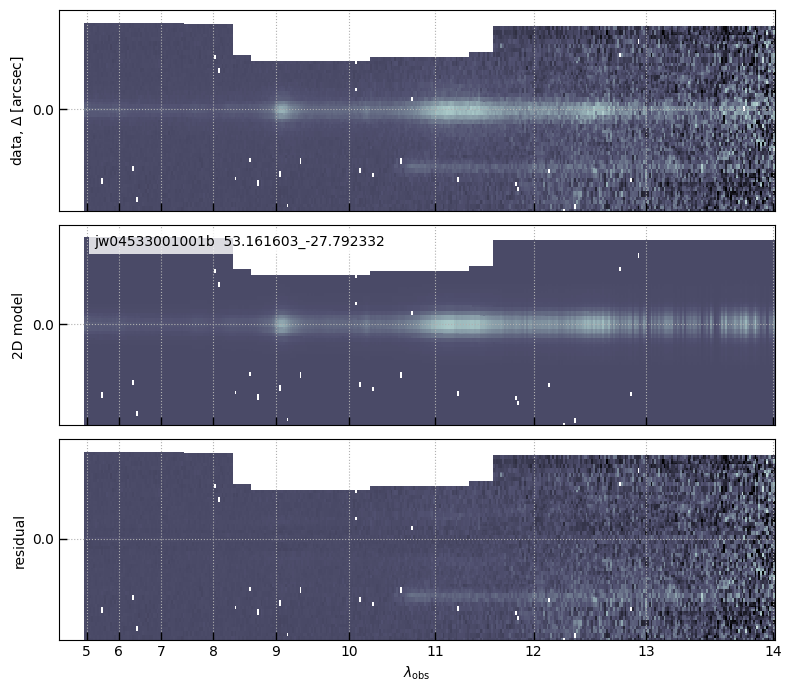

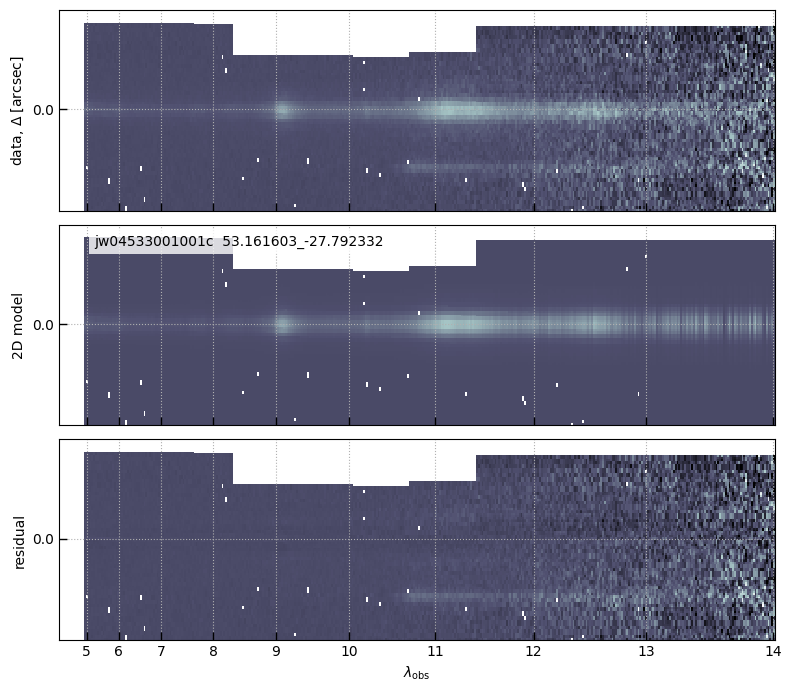

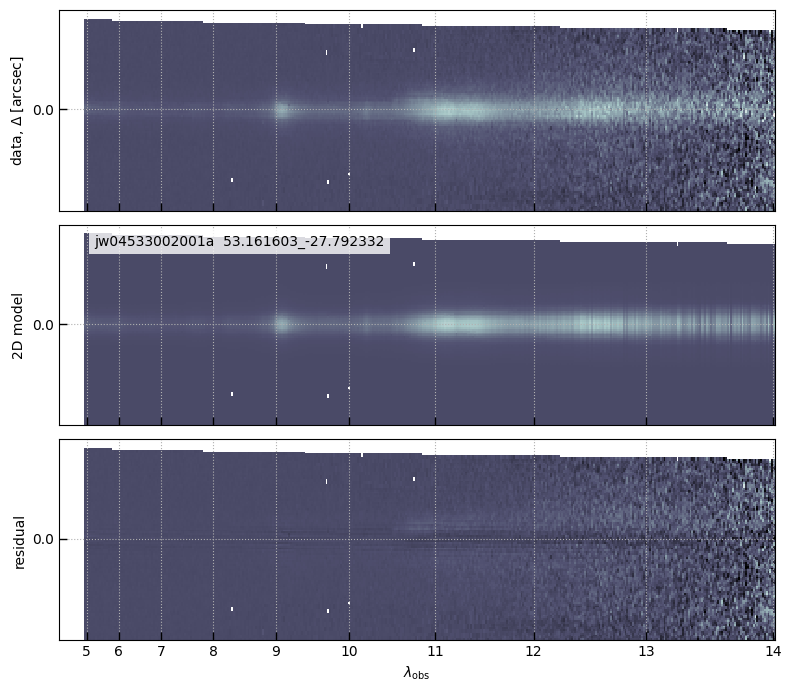

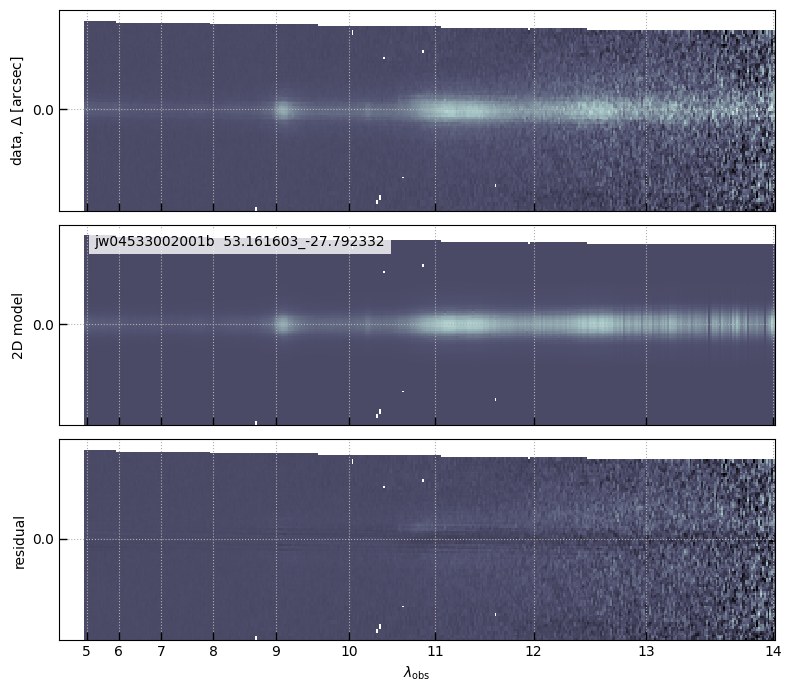

In [32]:

##########
# Full wavelength range for plots
xlim = None

if 0:
    xlim = (3.9, 12.1)

##########
# Redshift label
z = None

if 0:
    z = 0.3029
    
######

# Make sure separate thetas are set
lrs.set_full_profile(data, group_theta)

lrs.optimal_extraction(data, recenter=True)
hdu, fig = lrs.process_2d_products(data, prefix=f"{config['root']}_{pos_key}", xlim=xlim)

lspec = msaexp.spectrum.SpectrumSampler(hdu)
unit = "fnu"
summary_figs = {}
for unit in ["flam", "fnu"]:
    summary_figs[unit] = lspec.drizzled_hdu_figure(hdu, unit=unit, ny=12, xlim=xlim, z=z)

hdus = {}
lspecs = {}

# Show individual group extractions
if (ung.N > 1) & (1):
    for ig in group_theta:
        data_i = lrs.get_data_slice(data, ung[ig])
        
        lrs.optimal_extraction(data_i, recenter=True)
        hdu_i, fig = lrs.process_2d_products(data_i, prefix=f"{ig}_{pos_key}", xlim=xlim, make_figure=True)

        lspec_i = msaexp.spectrum.SpectrumSampler(hdu_i)
        for unit in summary_figs:
            msk = np.nan**(~lspec_i['valid'])
            summary_figs[unit].axes[2].step(np.arange(len(lspec_i["wave"])), lspec_i["flux"] * lspec_i["to_flam"]**(unit == "flam") * msk, alpha=0.5, zorder=-100)

        hdus[ig] = hdu_i
        lspecs[ig] = lspec_i

prefix = f"{config['root']}_{pos_key}_lrs.spec"

for unit in summary_figs:
    if ung.N > 1:
        for unit in summary_figs:
            msk = np.nan**(~lspec['valid'])
            summary_figs[unit].axes[2].step(np.arange(len(lspec["wave"])), lspec["flux"] * lspec["to_flam"]**(unit == "flam") * msk, alpha=0.3, zorder=100, color='k')

            summary_figs[unit].savefig(f"{prefix}.{unit}.png")


# PAH modeling

Fit for the source redshift using PAH templates with the lines from the CAFE [(Diaz-Santos 2025)](https://github.com/GOALS-survey/CAFE/tree/master/CAFE/tables)
PAH line list.

247it [00:03, 63.16it/s] 
167it [00:01, 89.09it/s]


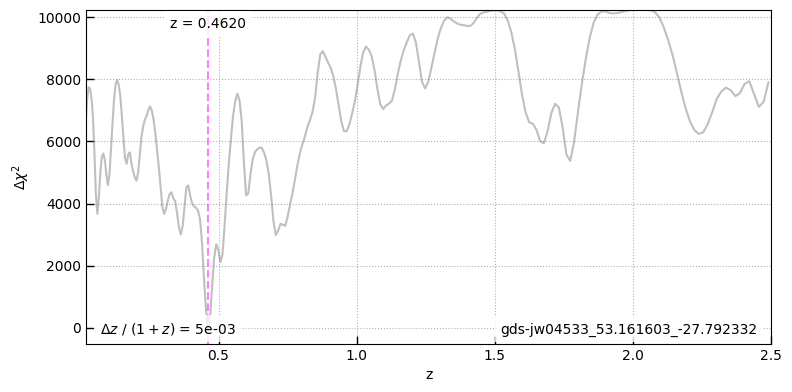

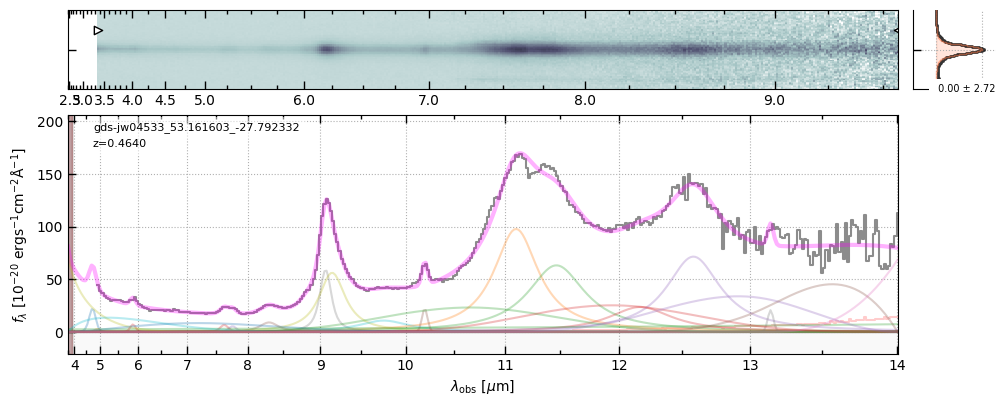

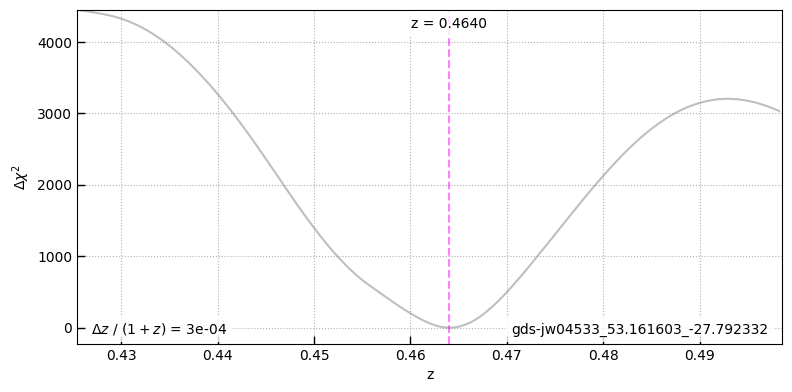

In [33]:
# B-Spline continuum templates
bspl = lspec.bspline_array(nspline=9, by_wavelength=False, orders=[1])

# seems like wavelength grid is often/always off by one pixel??
lspec.spec_wobs = lspec["wave"] + np.gradient(lspec["wave"])

fit_kwargs = dict(
    continuum_models=bspl, fitter="nnls",
    scale_disp=0.8
)

result = lrs.fit_lrs_redshift(lspec, zlim=(0.02, 2.5), dz=0.005, **fit_kwargs, make_plots=True)

next_zlim = result["zbest"] + np.array([-0.025, 0.025]) * (1 + result["zbest"])

result = lrs.fit_lrs_redshift(lspec, zlim=next_zlim, dz=0.0003, **fit_kwargs, make_plots=2)


In [34]:
# Break run all
print(xbreak)

NameError: name 'xbreak' is not defined

# Slit vs. slitless

One of the default examples includes exposures with the source both in the LRS slit and in the MIRIM_ILLUM slitless area.  Compare the two.

## Pathloss correction for the slit

A function is included to try to estimate the pathloss given the fit parameters.
Doesn't correct entirely, likely because the example source is significantly extended and the
correction assuming the Gaussian approximation of the morphology still misses light outside of the slit.

In [ ]:

data_slit = lrs.get_data_slice(data, data["in_slit"])

psf_data = lrs.evaluate_model_psf(
    data_slit, [0.0, 0.0], do_optimal_extraction=True
)

psf_dict = (psf_data["psf_mu"], psf_data["psf_width"])

ext_psf_dict = [
    psf_data[k]
    for k in ["sigma_scales", "sigma_widths", "psf_shifts", "sigma_coeffs"]
]

print(group_theta[ig])

path = lrs.profile_pathloss(
    data_slit, group_theta[ig],
    psf_data=psf_dict,
    extended_psf_data=ext_psf_dict,
    do_optimal_extraction=False,
    slit_width=0.51,
)

so = np.argsort(data_slit["wave"])

plt.plot(data_slit["wave"][so], path["pathloss"][so])
plt.xlabel("wavelength")
plt.ylabel("estimated pathloss")

lrs.optimal_extraction(data_slit, recenter=True)
hdu, fig = lrs.process_2d_products(data_slit, prefix=f"slit_{pos_key}", xlim=xlim, make_figure=False)
lspec_slit = msaexp.spectrum.SpectrumSampler(hdu)

# Apply the correction
data_slit["data"] /= path["pathloss"]

lrs.optimal_extraction(data_slit, recenter=True)
hdu, fig = lrs.process_2d_products(data_slit, prefix=f"slitpath_{pos_key}", xlim=xlim)

lspec_slit_pathcorr = msaexp.spectrum.SpectrumSampler(hdu)


# Slitless
data_slitless = lrs.get_data_slice(data, ~data["in_slit"])

lrs.optimal_extraction(data_slitless, recenter=True)

hdu, fig = lrs.process_2d_products(data_slitless, prefix=f"slitless_{pos_key}", xlim=xlim, make_figure=False)
lspec_slitless = msaexp.spectrum.SpectrumSampler(hdu)


In [ ]:
fig, ax = plt.subplots(1,1,figsize=(8,5))

ax.step(lspec_slit["wave"], lspec_slitless["flux"] * np.nan**(~lspec_slit["valid"]), label="Slitless", alpha=0.5)

ax.step(lspec_slit["wave"], lspec_slit_pathcorr["flux"] * np.nan**(~lspec_slit["valid"]) * 3, label="Slit, pathloss corrected x 3", alpha=0.5)

ax.step(lspec_slit["wave"], lspec_slit["flux"] * np.nan**(~lspec_slit["valid"]) * 3.5, label="Slit x 3.5", alpha=0.5)

ax.step(lspec_slit["wave"], lspec_slit_pathcorr["flux"] * np.nan**(~lspec_slit["valid"]), label="Slit, pathloss corrected", alpha=0.5)

ax.step(lspec_slit["wave"], lspec_slit["flux"] * np.nan**(~lspec_slit["valid"]), label="Slit", alpha=0.5)

ax.set_ylim(-0.1, 50)
ax.legend()

fig.tight_layout(pad=1)

# Plot in instrumental units

E.g., to investigate *additive* differences.

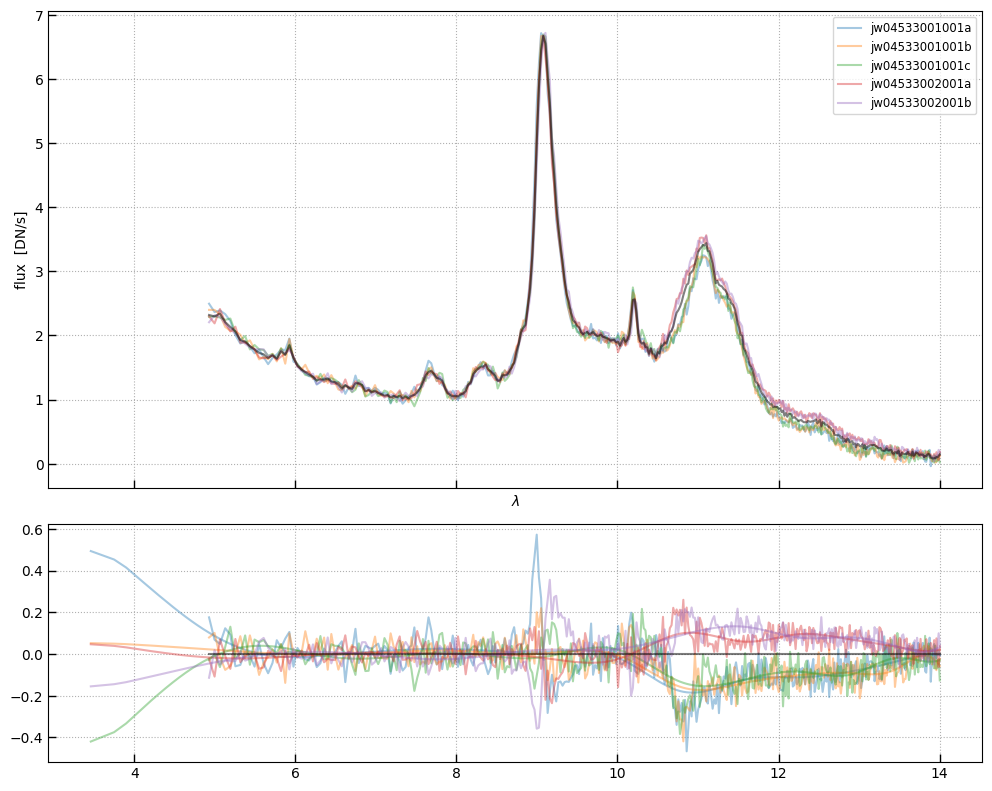

In [35]:
APPLY_SPLINE_CORRECTION = False

fig, axes = plt.subplots(2,1,figsize=(10,8), height_ratios=[1, 0.5], sharex=True)

axes[0].plot(lspec['wave'], lspec['flux_bin'] * lspec['calsp'] / data["unit_bin"], color='k', alpha=0.5, zorder=1001)

axes[1].plot(lspec['wave'], lspec['flux_bin'] * lspec['calsp'] * 0, color='k', alpha=0.5, zorder=1001)

xwbin = np.linspace(-1,1, len(data["wbin"]))
xwb = np.interp(data["wave"], data["wbin"], xwbin)

df = 13

bsplf = utils.bspline_templates(xwb, df=df, minmax=(-1,1), get_matrix=True)
bspl = utils.bspline_templates(xwbin, df=df, minmax=(-1,1), get_matrix=True).T

for ig in lspecs:
    lspec_i = lspecs[ig]
    pl = axes[0].plot(lspec_i['wave'], lspec_i['flux_bin'] * lspec_i['calsp'] / data["unit_bin"], alpha=0.4, label=ig)

    diff = (lspec_i['flux_bin'] - lspec['flux_bin']) * lspec_i['calsp'] / data["unit_bin"]
    ediff = lspec_i['err'] * lspec_i['calsp'] / data["unit_bin"]
    ok = np.isfinite(diff / ediff)
    
    c = np.linalg.lstsq((bspl / ediff).T[ok,:], (diff / ediff)[ok], rcond=None)
    splm = bspl.T.dot(c[0])

    if APPLY_SPLINE_CORRECTION:
        splmf = bsplf[ung[ig],:].dot(c[0])
        data["data"][ung[ig]] -= splmf
        
    pl = axes[1].plot(lspec_i['wave'], diff, alpha=0.4, label=ig)
    pl = axes[1].plot(lspec_i['wave'], splm, alpha=0.4, color=pl[0].get_color())

ax = axes[0]
ax.legend()
ax.grid()
ax.set_xlabel(r'$\lambda$')
ax.set_ylabel('flux  [DN/s]')

axes[1].grid()

fig.tight_layout(pad=1)
